# 🛠️ **IMPORTS**: Bibliotecas

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter

# 💻 **CÓDIGOS**: Implementação

In [9]:
file_censo = '../data/censo2022/br_ibge_censo_2022_municipio.xlsx'

df_censo = pd.read_excel(file_censo)
print("Arquivos carregados com sucesso.")

Arquivos carregados com sucesso.


In [10]:
df_taxa = df_censo[['taxa_alfabetizacao']].copy()
    
    # Conversão para numérico e remoção de valores nulos/erros
df_taxa['taxa_alfabetizacao'] = pd.to_numeric(df_taxa['taxa_alfabetizacao'], errors='coerce')
df_taxa.dropna(inplace=True)

# Limpeza de possíveis códigos de erro (como -9999)
df_taxa = df_taxa[df_taxa['taxa_alfabetizacao'] >= 0]

print(f"\nNúmero de municípios válidos para análise: {len(df_taxa)}")


Número de municípios válidos para análise: 5570


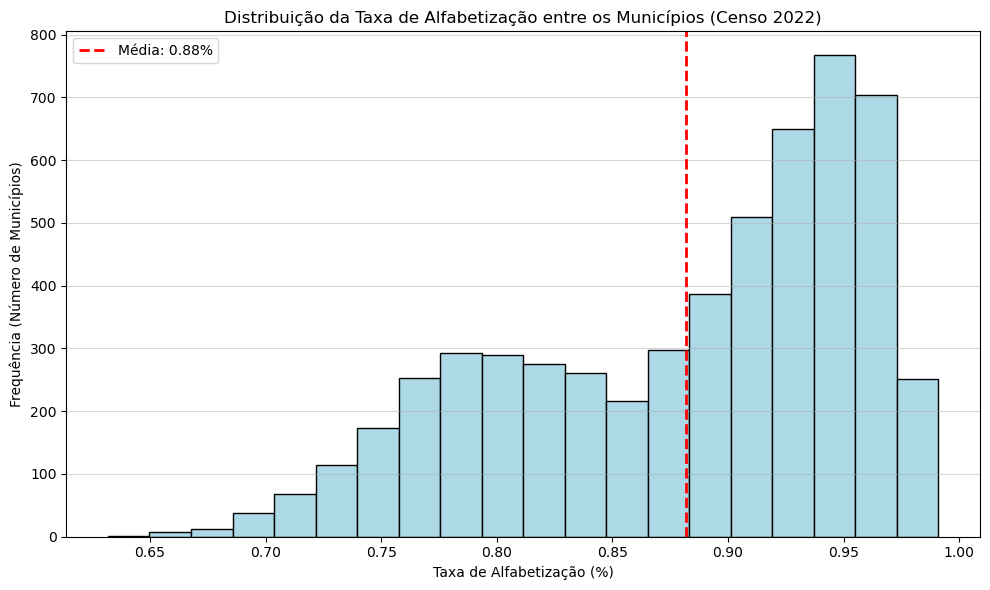

In [11]:
plt.figure(figsize=(10, 6))

plt.hist(
    df_taxa['taxa_alfabetizacao'], 
    bins=20, # 20 intervalos
    edgecolor='black', 
    color='lightblue'
)

media = df_taxa['taxa_alfabetizacao'].mean()
plt.axvline(media, color='red', linestyle='dashed', linewidth=2, label=f'Média: {media:.2f}%')

plt.title('Distribuição da Taxa de Alfabetização entre os Municípios (Censo 2022)')
plt.xlabel('Taxa de Alfabetização (%)')
plt.ylabel('Frequência (Número de Municípios)')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.show()